# 1. Import des bibliothèques

In [1]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input, Flatten
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt
import numpy as np

I0000 00:00:1792492416.228470   17853 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792492417.293876   17853 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792492424.623919   17853 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


1. TensorFlow : une bibliothèque pour créer et entraîner des modèles de machine learning.
Keras : une API qui facilite la création et l'entraînement des réseaux de neurones avec TensorFlow.

2. La couche Flatten transforme les données multidimensionnelles en un vecteur à une seule dimension, pour les transmettre aux couches suivantes.

3. La version installée est TensorFlow 2.22.0-rc0.

4. Sequential : permet de créer un modèle en ajoutant les couches les unes après les autres. Dense : représente une couche entièrement connectée où chaque neurone est connecté à tous les neurones de la couche précédente.

# 2. Chargement et préparation du dataset

In [2]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

x_train = x_train / 255.0
y_test = y_test / 255.0

print("x_train : ", x_train.shape)
print("y_train : ", y_train.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step 
x_train :  (60000, 28, 28)
y_train :  (60000,)


1. On normalise les pixels en divisant leurs valeurs par 255 pour obtenir des valeurs entre 0 et 1. Cela facilite et accélère l’entraînement du réseau de neurones.
2. Une image MNIST a une taille de 28 × 28 pixels et son type de données est généralement uint8 avant la normalisation, puis float32 après la normalisation.
3. Le jeu de données MNIST contient 60 000 images d’entraînement et 10 000 images de test.

# 3. Visualisation d’échantillons

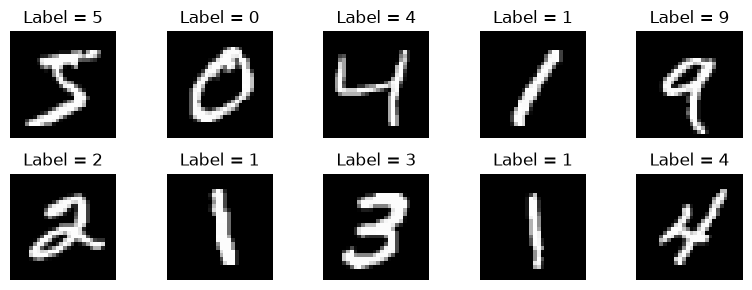

In [3]:
plt.figure(figsize=(8, 3))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.axis('off')
    plt.title(f"Label = {y_train[i]}")

plt.tight_layout()
plt.show()

1. La commande plt.subplots() permet de définir le nombre de lignes et de colonnes pour afficher les images.
2. Il permet d’afficher les images en niveaux de gris (noir et blanc).
3. Elle permet de visualiser les données, de vérifier leur qualité et de mieux comprendre les images avant d’entraîner le modèle.

# 4. Construction du modèle de réseau de neurones

In [4]:
model = tf.keras.Sequential([
    Input(shape=(28,28)),
    Flatten(),
    Dense(128, activation="relu"),
    Dense(10, activation="softmax")
])

model.summary()

E0000 00:00:1792492432.980635   17853 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

1. Cela dépend de l’architecture du modèle. Pour un modèle MNIST avec Flatten, Dense(128) et Dense(10), il contient 101 770 paramètres.
2. QLa fonction utilisée est Softmax. Elle transforme les sorties en probabilités pour les 10 classes de chiffres (0 à 9).
3. ReLU : transforme les valeurs négatives en 0 et conserve les valeurs positives. Elle est souvent utilisée dans les couches cachées.  Softmax : transforme les sorties en probabilités dont la somme est égale à 1. Elle est souvent utilisée dans la couche de sortie pour la classification.

# 5. Compilation du modèle

In [5]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

1. Un optimiseur ajuste les poids du réseau de neurones pour réduire l’erreur et améliorer les prédictions.
2. La fonction de perte mesure l’écart entre les prédictions du modèle et les valeurs réelles.
3. Le modèle apprend différemment, car la méthode de calcul de l’erreur change. Cela peut améliorer ou diminuer ses performances.
4. L’apprentissage peut devenir lent, instable ou ne pas converger vers une solution satisfaisante.
5.  Loss : mesure l’erreur utilisée pour guider l’apprentissage du modèle. Metrics : mesurent les performances du modèle, par exemple la précision (accuracy).

# 6. Entraînement du modèle

In [6]:
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_data=(x_test, y_test)
)

Epoch 1/5


W0000 00:00:1792492435.374654   17853 cpu_allocator_impl.cc:174] Allocation of 188160000 exceeds 10% of free system memory.


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 24s 12ms/step - accuracy: 0.9242 - loss: 0.2628 - val_accuracy: 0.0968 - val_loss: 2463.7222
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 21s 11ms/step - accuracy: 0.9661 - loss: 0.1142 - val_accuracy: 0.0972 - val_loss: 2797.0835
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 33s 7ms/step - accuracy: 0.9768 - loss: 0.0774 - val_accuracy: 0.0969 - val_loss: 3249.8005
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.9829 - loss: 0.0575 - val_accuracy: 0.0972 - val_loss: 3666.6643
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.9877 - loss: 0.0432 - val_accuracy: 0.0971 - val_loss: 4149.2822


1. Une époque (epoch) correspond à un passage complet sur toutes les données d’entraînement.
2. Il permet d’évaluer les performances du modèle pendant l’entraînement et de détecter le surapprentissage (overfitting).
3. Le modèle pourrait apprendre davantage et améliorer sa précision, mais il risque aussi le surapprentissage et un temps d’entraînement plus long.

# 7. Évaluation du modèle

In [7]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Loss :", test_loss)
print("Accuracy :", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0971 - loss: 4149.2822 
Loss : 4149.2822265625
Accuracy : 0.09709999710321426


1. Elle correspond à la valeur de accuracy obtenue lors de l’évaluation sur le jeu de test avec model.evaluate().
2. Parce que le modèle apprend sur les données d’entraînement, mais doit généraliser à de nouvelles données qu’il n’a jamais vues.
3.  Réduire le nombre d’époques.  Ajouter du Dropout. Utiliser davantage de données d’entraînement. Appliquer l’Early Stopping pour arrêter l’entraînement au bon moment.

# 8. Visualisation des performances

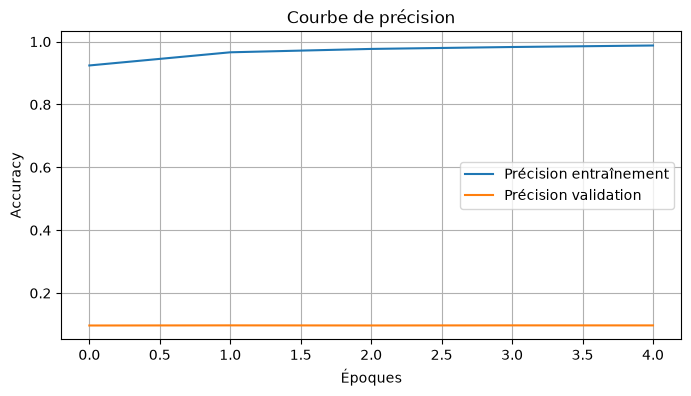

In [8]:
plt.figure(figsize=(8, 4))

plt.plot(history.history['accuracy'], label='Précision entraînement')
plt.plot(history.history['val_accuracy'], label='Précision validation')

plt.title('Courbe de précision')
plt.xlabel('Époques')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()

1. La courbe d’entraînement représente la précision sur les données d’entraînement, tandis que celle de validation représente la précision sur des données non utilisées pour entraîner le modèle.
2. Lorsque la précision d’entraînement continue d’augmenter, mais que celle de validation stagne ou diminue.
3. Utiliser le Dropout, l’Early Stopping ou augmenter les données d’entraînement.
4. Vérifier l’écart entre les deux courbes et utiliser des techniques de régularisation pour améliorer la généralisation du modèle.

# 9. Prédictions et visualisation

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step 


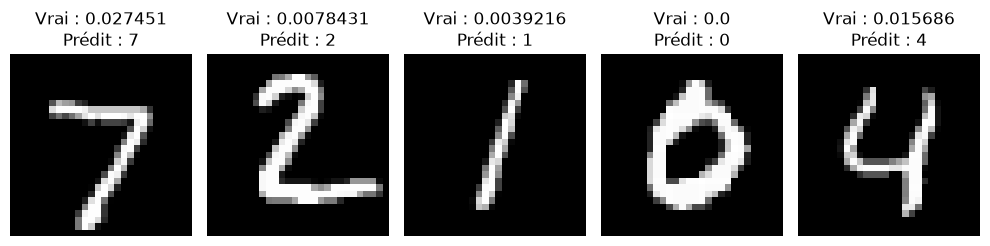

In [11]:
predictions = model.predict(x_test)

plt.figure(figsize=(10, 4))

for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_test[i], cmap='gray')
    plt.title(f"Vrai : {y_test[i]:.5}\nPrédit : {np.argmax(predictions[i])}")
    plt.axis('off')

plt.tight_layout()
plt.show()

1. Oui, si la valeur prédite est différente de la valeur réelle (Vrai). Les erreurs sont visibles sur les images où les deux valeurs diffèrent.

2. L’image peut être mal écrite, difficile à reconnaître ou ressembler à un autre chiffre.

3. Utiliser un CNN (réseau de neurones convolutif), mieux adapté à la reconnaissance d’images, et entraîner le modèle avec suffisamment de données.